# Tổng hợp perturbation XAI cho VG và PSG



In [1]:
from pathlib import Path
import csv, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import drive
drive.mount('/content/drive')
DRIVE = Path('/content/drive/MyDrive')
RUNS = DRIVE / 'graphml-project3/duong/runs/qa_vg_psg_xai'
RESULTS_DIR = None  # hoặc đặt Path('/content/drive/MyDrive/.../xai-YYYYMMDD-HHMMSS')
if RESULTS_DIR is None:
    complete = sorted((p.parent for p in RUNS.glob('xai-*/summary.json')
                       if all((p.parent / name).is_file() for name in
                              ('xai_results.csv', 'selected_cases.json', 'explanations.json'))),
                      key=lambda p: p.stat().st_mtime)
    assert complete, f'Không tìm thấy lượt XAI hoàn tất trong {RUNS}'
    RESULTS_DIR = complete[-1]
RESULTS_DIR = Path(RESULTS_DIR)
ANALYSIS = RESULTS_DIR / 'analysis'
ANALYSIS.mkdir(exist_ok=True)
print('XAI:', RESULTS_DIR, '| report:', ANALYSIS)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
XAI: /content/drive/MyDrive/graphml-project3/duong/runs/qa_vg_psg_xai/xai-20261121-130842 | report: /content/drive/MyDrive/graphml-project3/duong/runs/qa_vg_psg_xai/xai-20261121-130842/analysis


In [2]:
summary = json.loads((RESULTS_DIR / 'summary.json').read_text())
selected = json.loads((RESULTS_DIR / 'selected_cases.json').read_text())
explanations = json.loads((RESULTS_DIR / 'explanations.json').read_text())
manifest = json.loads(Path(summary['training_manifest']).read_text())
raw = pd.read_csv(RESULTS_DIR / 'xai_results.csv')
assert len(raw) == summary['n_rows'] == 216
assert len(selected) == summary['n_selected_cases'] == 24
assert len(explanations) == 216
case_index = {(c['dataset'], int(c['caption_id'])): int(c['candidate_row']) for c in selected}
assert len(case_index) == 24
SELECTION_SEED, MODEL_SEED_STEP, ROW_SEED_STEP = 42, 100000, 10

def recover_seeds(row):
    stored = int(row['seed'])
    if stored in (0, 1, 2):
        model_seed = stored
        random_seed = int(row['random_seed']) if 'random_seed' in row and pd.notna(row['random_seed']) else None
    else:
        j = case_index[row['dataset'], int(row['caption_id'])]
        offset = stored - SELECTION_SEED - j * ROW_SEED_STEP - int(row['requested_k'])
        assert offset % MODEL_SEED_STEP == 0, ('Không thể khôi phục model seed', row.to_dict())
        model_seed, random_seed = offset // MODEL_SEED_STEP, stored
    assert model_seed in (0, 1, 2)
    return pd.Series({'model_seed': model_seed, 'random_seed_fixed': random_seed})

fixed = raw.copy()
fixed['seed_original'] = fixed['seed']
fixed[['model_seed', 'random_seed_fixed']] = fixed.apply(recover_seeds, axis=1)
fixed['seed'] = fixed['model_seed'].astype(int)
fixed['random_seed'] = fixed['random_seed_fixed'].astype('Int64')
fixed = fixed.drop(columns=['random_seed_fixed'])
keys = ['dataset', 'caption_id', 'model_seed', 'requested_k']
assert not fixed.duplicated(keys).any()
assert fixed.groupby(['dataset','caption_id']).size().eq(9).all()
assert fixed.groupby(['dataset','model_seed','requested_k']).size().eq(12).all()
ex_keys = {(e['dataset'], int(e['caption_id']), int(e['seed']), int(e['requested_k']))
           for e in explanations}
assert ex_keys == set(map(tuple, fixed[keys].itertuples(index=False, name=None)))
for item in summary['summary']:
    subset = fixed[(fixed.dataset == item['dataset']) & (fixed.group == item['group'])
                   & (fixed.seed0_outcome == item['seed0_outcome'])
                   & (fixed.requested_k == item['k'])]
    assert len(subset) == item['n']
    assert math.isclose(subset.final_score_drop.mean(), item['mean_final_drop'], abs_tol=1e-8)
    assert math.isclose(subset.random_final_score_drop_mean.mean(), item['mean_random_drop'], abs_tol=1e-8)
    assert math.isclose(subset.fidelity_advantage.mean(), item['mean_advantage'], abs_tol=1e-8)
print('Đã đối chiếu', len(fixed), 'dòng,', len(explanations), 'explanation và', len(summary['summary']), 'nhóm summary.')
print('CSV gốc dùng random seed trong cột seed:', bool((raw['seed'] > 2).any()))


Đã đối chiếu 216 dòng, 216 explanation và 24 nhóm summary.
CSV gốc dùng random seed trong cột seed: True


In [3]:
fixed['top1_changed'] = fixed['rank_after'] > 1
fixed['gt_improved'] = fixed['gt_rank_after'] < fixed['gt_rank_before']
fixed['gt_worsened'] = fixed['gt_rank_after'] > fixed['gt_rank_before']
fixed['coverage_pct'] = 100 * fixed['screen_coverage']
fixed['sparsity_pct'] = 100 * fixed['sparsity']
fixed['has_path'] = fixed['n_explained_paths'] > 0
fixed['advantage_positive'] = fixed['fidelity_advantage'] > 0
aggregate = dict(n=('caption_id','size'), actual_k=('k','mean'),
                 final_drop=('final_score_drop','mean'), random_drop=('random_final_score_drop_mean','mean'),
                 advantage=('fidelity_advantage','mean'), positive_advantage=('advantage_positive','mean'),
                 top1_changed=('top1_changed','mean'), gt_improved=('gt_improved','mean'),
                 gt_worsened=('gt_worsened','mean'), coverage_pct=('coverage_pct','mean'),
                 sparsity_pct=('sparsity_pct','mean'), structural_validity=('structural_validity','mean'),
                 evidence_known=('evidence_known_rate','mean'), with_path=('has_path','mean'))
overall = fixed.groupby(['dataset','requested_k'], as_index=False).agg(**aggregate)
strata = fixed.groupby(['dataset','group','seed0_outcome','requested_k'], as_index=False).agg(**aggregate)
by_seed = fixed.groupby(['dataset','model_seed','requested_k'], as_index=False).agg(**aggregate)
training = pd.DataFrame([{'dataset': r['dataset'], 'model_seed': int(r['seed']),
                          'alpha': r['alpha'], 'test_full_MRR': r['test_full_MRR']}
                         for r in manifest['runs']]).sort_values(['dataset','model_seed'])
assert len(training) == 6
print('Checkpoint / retrieval gốc:'); display(training.round(3))
print('XAI tổng thể (mỗi dòng gồm 12 caption × 3 seed):'); display(overall.round(3))
print('Theo direct/indirect và outcome xác định ở seed 0:'); display(strata.round(3))
print('Theo model seed:'); display(by_seed.round(3))


Checkpoint / retrieval gốc:


,dataset,model_seed,alpha,test_full_MRR
3,psg,0,0.30,64.424
4,psg,1,0.20,64.352
5,psg,2,0.25,64.184
0,vg,0,0.30,65.092
1,vg,1,0.30,64.803
2,vg,2,0.30,64.762


XAI tổng thể (mỗi dòng gồm 12 caption × 3 seed):


,dataset,requested_k,n,actual_k,final_drop,random_drop,advantage,positive_advantage,top1_changed,gt_improved,gt_worsened,coverage_pct,sparsity_pct,structural_validity,evidence_known,with_path
0,psg,1,36,1.0,0.901,0.178,0.723,1.000,0.778,0.278,0.250,0.477,97.885,1.0,0.0,1.0
1,psg,3,36,3.0,1.723,0.726,0.996,1.000,0.944,0.500,0.389,0.477,93.655,1.0,0.0,1.0
2,psg,5,36,5.0,1.726,1.012,0.715,0.861,0.889,0.472,0.333,0.477,89.425,1.0,0.0,1.0
3,vg,1,36,1.0,0.490,0.050,0.440,1.000,0.694,0.139,0.167,0.869,98.228,1.0,0.0,1.0
4,vg,3,36,3.0,0.902,0.173,0.729,1.000,0.806,0.194,0.194,0.869,94.684,1.0,0.0,1.0
5,vg,5,36,5.0,1.062,0.220,0.843,1.000,0.833,0.278,0.222,0.869,91.140,1.0,0.0,1.0


Theo direct/indirect và outcome xác định ở seed 0:


,dataset,group,seed0_outcome,requested_k,n,actual_k,final_drop,random_drop,advantage,positive_advantage,top1_changed,gt_improved,gt_worsened,coverage_pct,sparsity_pct,structural_validity,evidence_known,with_path
0,psg,direct,failure,1,9,1.0,1.271,0.232,1.040,1.000,1.000,0.889,0.000,0.483,97.813,1.0,0.0,1.0
1,psg,direct,failure,3,9,3.0,1.788,0.807,0.981,1.000,1.000,1.000,0.000,0.483,93.438,1.0,0.0,1.0
2,psg,direct,failure,5,9,5.0,1.441,0.770,0.670,0.889,1.000,0.667,0.000,0.483,89.063,1.0,0.0,1.0
3,psg,direct,success,1,9,1.0,0.782,0.204,0.578,1.000,0.333,0.222,0.111,0.501,97.884,1.0,0.0,1.0
4,psg,direct,success,3,9,3.0,1.856,0.933,0.924,1.000,0.778,0.222,0.556,0.501,93.653,1.0,0.0,1.0
5,psg,direct,success,5,9,5.0,1.598,1.144,0.455,0.778,0.667,0.222,0.444,0.501,89.422,1.0,0.0,1.0
6,psg,indirect,failure,1,9,1.0,0.664,0.112,0.552,1.000,0.889,0.000,0.000,0.475,98.002,1.0,0.0,1.0
7,psg,indirect,failure,3,9,3.0,1.481,0.461,1.020,1.000,1.000,0.778,0.000,0.475,94.007,1.0,0.0,1.0
8,psg,indirect,failure,5,9,5.0,1.822,0.900,0.923,1.000,1.000,1.000,0.000,0.475,90.012,1.0,0.0,1.0
9,psg,indirect,success,1,9,1.0,0.888,0.165,0.723,1.000,0.889,0.000,0.889,0.451,97.840,1.0,0.0,1.0


Theo model seed:


,dataset,model_seed,requested_k,n,actual_k,final_drop,random_drop,advantage,positive_advantage,top1_changed,gt_improved,gt_worsened,coverage_pct,sparsity_pct,structural_validity,evidence_known,with_path
0,psg,0,1,12,1.0,0.852,0.190,0.662,1.000,0.833,0.250,0.333,0.474,97.867,1.0,0.0,1.0
1,psg,0,3,12,3.0,1.604,0.652,0.952,1.000,0.917,0.417,0.417,0.474,93.600,1.0,0.0,1.0
2,psg,0,5,12,5.0,1.383,0.833,0.550,0.833,0.833,0.333,0.333,0.474,89.334,1.0,0.0,1.0
3,psg,1,1,12,1.0,0.970,0.144,0.826,1.000,0.833,0.333,0.250,0.480,97.905,1.0,0.0,1.0
4,psg,1,3,12,3.0,1.841,0.731,1.110,1.000,1.000,0.583,0.417,0.480,93.716,1.0,0.0,1.0
5,psg,1,5,12,5.0,1.983,1.115,0.868,0.833,0.917,0.583,0.333,0.480,89.527,1.0,0.0,1.0
6,psg,2,1,12,1.0,0.883,0.200,0.682,1.000,0.667,0.250,0.167,0.479,97.882,1.0,0.0,1.0
7,psg,2,3,12,3.0,1.723,0.796,0.927,1.000,0.917,0.500,0.333,0.479,93.647,1.0,0.0,1.0
8,psg,2,5,12,5.0,1.814,1.087,0.727,0.917,0.917,0.500,0.333,0.479,89.412,1.0,0.0,1.0
9,vg,0,1,12,1.0,0.481,0.038,0.443,1.000,0.667,0.000,0.333,0.902,98.200,1.0,0.0,1.0


In [4]:
# Lấy mẫu lại caption, giữ ba seed của mỗi caption cùng nhau (12 cụm/dataset).
rng = np.random.default_rng(20261121)
ci_rows = []
for (dataset, k), subset in fixed.groupby(['dataset','requested_k']):
    case_means = subset.groupby('caption_id')['fidelity_advantage'].mean().to_numpy()
    assert len(case_means) == 12
    draws = rng.choice(case_means, size=(5000, len(case_means)), replace=True).mean(axis=1)
    lo, hi = np.quantile(draws, [0.025, 0.975])
    ci_rows.append({'dataset': dataset, 'k': int(k), 'n_captions': len(case_means),
                    'mean_advantage': float(case_means.mean()),
                    'bootstrap_low': float(lo), 'bootstrap_high': float(hi)})
advantage_ci = pd.DataFrame(ci_rows).sort_values(['dataset','k'])
print('Fidelity advantage, bootstrap 95% CI theo caption:'); display(advantage_ci.round(3))
print('CI mô tả 12 caption đã chọn, không suy rộng ra toàn bộ test.')


Fidelity advantage, bootstrap 95% CI theo caption:


,dataset,k,n_captions,mean_advantage,bootstrap_low,bootstrap_high
0,psg,1,12,0.723,0.547,0.914
1,psg,3,12,0.996,0.878,1.104
2,psg,5,12,0.715,0.488,0.928
3,vg,1,12,0.440,0.288,0.644
4,vg,3,12,0.729,0.561,0.931
5,vg,5,12,0.843,0.686,1.014


CI mô tả 12 caption đã chọn, không suy rộng ra toàn bộ test.


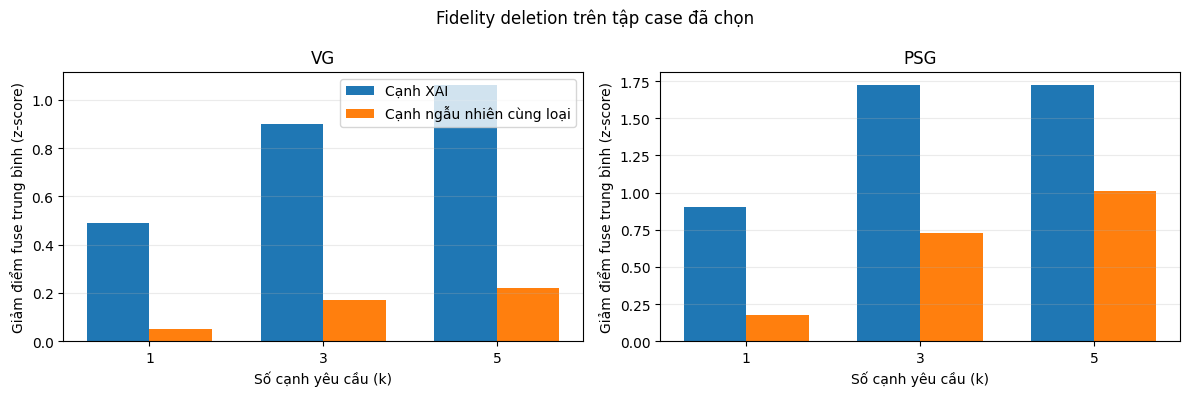

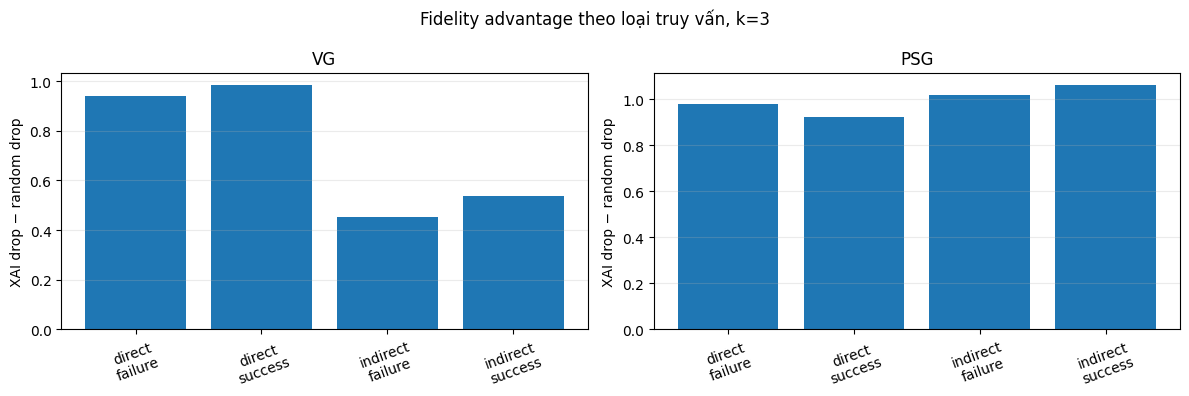

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, dataset in zip(axes, ('vg', 'psg')):
    part = overall[overall.dataset == dataset].sort_values('requested_k')
    xs = np.arange(len(part)); width = 0.36
    ax.bar(xs-width/2, part.final_drop, width, label='Cạnh XAI')
    ax.bar(xs+width/2, part.random_drop, width, label='Cạnh ngẫu nhiên cùng loại')
    ax.set_xticks(xs, part.requested_k.astype(str))
    ax.set_title(dataset.upper()); ax.set_xlabel('Số cạnh yêu cầu (k)')
    ax.set_ylabel('Giảm điểm fuse trung bình (z-score)')
    ax.grid(axis='y', alpha=0.25)
axes[0].legend(); fig.suptitle('Fidelity deletion trên tập case đã chọn')
fig.tight_layout(); fig.savefig(ANALYSIS / 'fidelity_vs_random.png', dpi=160)
display(fig); plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, dataset in zip(axes, ('vg', 'psg')):
    part = strata[(strata.dataset == dataset) & (strata.requested_k == 3)].copy()
    labels = part['group'] + '\n' + part['seed0_outcome']
    ax.bar(labels, part.advantage)
    ax.set_title(dataset.upper()); ax.set_ylabel('XAI drop − random drop')
    ax.tick_params(axis='x', labelrotation=20)
    ax.grid(axis='y', alpha=0.25)
fig.suptitle('Fidelity advantage theo loại truy vấn, k=3')
fig.tight_layout(); fig.savefig(ANALYSIS / 'advantage_by_group.png', dpi=160)
display(fig); plt.close(fig)


In [6]:
label_names = {}
for dataset in ('vg','psg'):
    path = DRIVE / f'mmxai_{dataset}_bundle/huy_extra_cn/labels.json'
    label_names[dataset] = json.loads(path.read_text()) if path.is_file() else []
ex_index = {(e['dataset'], int(e['caption_id']), int(e['seed']), int(e['requested_k'])):
            e['explanation'] for e in explanations}

def node_name(dataset, node):
    if node.startswith('label:') and label_names[dataset]:
        return label_names[dataset][int(node.split(':',1)[1])]
    return node

def edge_text(dataset, explanation):
    rows = []
    for edge in explanation['edges']:
        src = node_name(dataset, edge['source']); dst = node_name(dataset, edge['target'])
        rows.append(f"{src} -[{edge['relation']}]-> {dst}")
    return '; '.join(rows)

representatives = []
for (dataset, group, outcome), part in fixed[(fixed.model_seed == 0) & (fixed.requested_k == 3)].groupby(
        ['dataset','group','seed0_outcome']):
    midpoint = part.fidelity_advantage.median()
    row = part.iloc[(part.fidelity_advantage-midpoint).abs().argmin()]
    ex = ex_index[dataset, int(row.caption_id), 0, 3]
    representatives.append({'dataset': dataset, 'group': group, 'seed0_outcome': outcome,
        'caption_id': int(row.caption_id), 'query': row['query'],
        'top_image_id': row['image_id'], 'gt_image_id': row['ground_truth_image_id'],
        'gt_rank_before': int(row.gt_rank_before), 'gt_rank_after': int(row.gt_rank_after),
        'top_rank_after': int(row.rank_after), 'advantage': row.fidelity_advantage,
        'edges': edge_text(dataset, ex)})
case_table = pd.DataFrame(representatives).sort_values(['dataset','group','seed0_outcome'])
pd.set_option('display.max_colwidth', 140)
print('Case tiêu biểu (seed 0, k=3; gần median advantage của mỗi nhóm):')
display(case_table.round(3))


Case tiêu biểu (seed 0, k=3; gần median advantage của mỗi nhóm):


,dataset,group,seed0_outcome,caption_id,query,top_image_id,gt_image_id,gt_rank_before,gt_rank_after,top_rank_after,advantage,edges
0,psg,direct,failure,76884,A person sits on top of a motorcycle with others.,4491,15368,13,12,46,0.887,motorcycle -[contains]-> image:4491; person -[contains]-> image:4491; road -[contains]-> image:4491
1,psg,direct,success,58392,A horse walks between cars in a parking lot.,11672,11672,1,1,1,1.041,horse -[contains]-> image:11672; car -[contains]-> image:11672; road -[contains]-> image:11672
2,psg,indirect,failure,73603,A group of women playing video games together,14686,14713,13,12,13,1.062,remote -[contains]-> image:14686; person -[contains]-> image:14686; tv -[contains]-> image:14686
3,psg,indirect,success,66698,A man walking down the street carrying a suitcase.,13333,13333,1,4,4,0.907,suitcase -[contains]-> image:13333; person -[contains]-> image:13333; pavement -[contains]-> image:13333
4,vg,direct,failure,85390,Two zebras and another animal grazing in the grass.,18104,17067,11,10,15,0.935,zebra -[contains]-> image:18104; antelope -[contains]-> image:18104; grass -[contains]-> image:18104
5,vg,direct,success,6120,several people hold umbrellas in a rain storm,1223,1223,1,8,8,0.906,umbrella -[contains]-> image:1223; rain -[contains]-> image:1223; people -[contains]-> image:1223
6,vg,indirect,failure,47795,a giraffe in an enclosure at an animal park.,4068,9552,20,20,7,0.450,giraffe -[contains]-> image:4068; zebra -[contains]-> image:4068; fence -[contains]-> image:4068
7,vg,indirect,success,68975,Car buried in snow next to what might be a gas pump.,13786,13786,1,1,1,0.583,car -[contains]-> image:13786; snow -[contains]-> image:13786; meter -[contains]-> image:13786


In [7]:
fixed.to_csv(ANALYSIS / 'xai_results_corrected.csv', index=False)
for (dataset, seed), part in fixed.groupby(['dataset','model_seed']):
    (ANALYSIS / f'{dataset}_seed{seed}_corrected.json').write_text(
        part.to_json(orient='records', force_ascii=False, indent=2), encoding='utf-8')
overall.to_csv(ANALYSIS / 'overall.csv', index=False)
strata.to_csv(ANALYSIS / 'by_group_outcome.csv', index=False)
by_seed.to_csv(ANALYSIS / 'by_model_seed.csv', index=False)
advantage_ci.to_csv(ANALYSIS / 'advantage_bootstrap_ci.csv', index=False)
case_table.to_csv(ANALYSIS / 'representative_cases.csv', index=False)
training.to_csv(ANALYSIS / 'training_baseline.csv', index=False)

def markdown_table(frame, columns):
    head = '| ' + ' | '.join(columns) + ' |'
    rule = '| ' + ' | '.join('---' for _ in columns) + ' |'
    body = ['| ' + ' | '.join(f'{value:.3f}' if isinstance(value, float) else str(value)
                               for value in row) + ' |'
            for row in frame[columns].itertuples(index=False, name=None)]
    return '\n'.join([head, rule, *body])

report = ['# Tổng hợp XAI VG và PSG', '',
          f'Nguồn: `{RESULTS_DIR}`; {len(selected)} caption, 3 model seed, k=1/3/5; '
          f'{len(fixed)} dòng. Random baseline: {summary["random_repeats"]} lượt, khớp loại cạnh.', '',
          '## Tổng thể', '',
          markdown_table(overall.round(3), ['dataset','requested_k','n','final_drop','random_drop',
                                             'advantage','top1_changed','gt_improved','coverage_pct']), '',
          '## Theo model seed', '',
          markdown_table(by_seed.round(3), ['dataset','model_seed','requested_k','n',
                                             'final_drop','random_drop','advantage']), '',
          '## Theo nhóm truy vấn và outcome seed 0', '',
          markdown_table(strata.round(3), ['dataset','group','seed0_outcome','requested_k','n',
                                            'final_drop','random_drop','advantage']), '',
          '## Bootstrap 95% CI theo caption', '',
          markdown_table(advantage_ci.round(3), ['dataset','k','n_captions','mean_advantage',
                                                  'bootstrap_low','bootstrap_high']), '',
          '## Case tiêu biểu (seed 0, k=3)', '',
          markdown_table(case_table.round(3), ['dataset','group','seed0_outcome','caption_id',
                                                 'gt_rank_before','gt_rank_after','advantage','edges']), '',
          '## Giới hạn', '',
          '- Chọn 12 caption mỗi dataset theo outcome seed 0; không suy rộng ra toàn bộ test.',
          '- Một caption xuất hiện ở ba seed; CI lấy mẫu theo caption để giữ cụm này.',
          '- VG và PSG có dữ liệu, GNN và tập cạnh khác nhau; không quy chênh lệch chỉ cho dataset.',
          '- Coverage là tỷ lệ cạnh vùng 2-hop được xét; structural validity không xác nhận hỗ trợ thị giác.',
          '- Top-1 đổi hạng không nhất thiết làm ảnh đúng tăng hạng.',
          '- CSV gốc được giữ nguyên; `xai_results_corrected.csv` tách model seed và random seed.', '']
(ANALYSIS / 'report.md').write_text('\n'.join(report), encoding='utf-8')
print('Đã lưu report, bảng CSV và hai biểu đồ tại:', ANALYSIS)


Đã lưu report, bảng CSV và hai biểu đồ tại: /content/drive/MyDrive/graphml-project3/duong/runs/qa_vg_psg_xai/xai-20261121-130842/analysis
